In [29]:
print("My POE notebook is ready")

My POE notebook is ready


In [30]:
import pandas as pd

# Load the original data before making any changes
df = pd.read_csv("hospital.csv")

# Display the dataset size and first five rows
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (996, 4)


,Feedback,Sentiment Label,Ratings,Unnamed: 3
0,Good and clean hospital. There is great team of doctors and good OT facility. The medical facilities are all great with good in-patient post opera...,1,5,NaN
1,Had a really bad experience during discharge. They need to be sensitive and more transparent towards the patient and his/her family.,1,5,NaN
2,I have visited to take my second dose and Process was really smooth. Hospitality from all staffs are really appreciable. Shanti tooks good care an...,1,4,NaN
3,"That person was slightly clueless and offered only one package. But once i got to the hospital, I found a better and more economical one and deci...",1,3,NaN
4,There is great team of doctors and good OT facility.,0,1,NaN


## 3. Initial Data Exploration

I will check the dataset's structure, missing values, duplicate rows,
sentiment labels and ratings before cleaning the data.

In [31]:
# Check column names, data types and non-missing values
df.info()

# Count missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# Count exact duplicate rows
print("\nExact duplicate rows:", df.duplicated().sum())

# Check the distribution of the supplied labels
print("\nSentiment label counts:")
print(df["Sentiment Label"].value_counts())

# Check the distribution of star ratings
print("\nRating counts:")
print(df["Ratings"].value_counts().sort_index())

<class 'pandas.DataFrame'>
RangeIndex: 996 entries, 0 to 995
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Feedback         996 non-null    str    
 1   Sentiment Label  996 non-null    int64  
 2   Ratings          996 non-null    int64  
 3   Unnamed: 3       0 non-null      float64
dtypes: float64(1), int64(2), str(1)
memory usage: 27.3 KB

Missing values:
Feedback             0
Sentiment Label      0
Ratings              0
Unnamed: 3         996
dtype: int64

Exact duplicate rows: 19

Sentiment label counts:
Sentiment Label
1    728
0    268
Name: count, dtype: int64

Rating counts:
Ratings
1    123
2    145
3    123
4    254
5    351
Name: count, dtype: int64


### Initial Data Quality Findings

The original dataset contains 996 rows and four columns. Feedback,
Sentiment Label and Ratings each contain 996 non-missing values.
The additional column, Unamed: 3, is entirely empty and will be removed.

There are 19 exact duplicate rows, which will also be removed.
The original sentiment-label counts are 728 for label 1 and 268 for
label 0, showing an uneven distribution.

Ratings range from 1 to 5. Five-star reviews are the most frequent,
with 351 reviews. These counts describe the original dataset before
cleaning and will be checked again after duplicate removal.

In [32]:
# Keep the original dataframe unchanged
df_clean = df.copy()

# Remove the completely empty column
df_clean = df_clean.drop(columns=["Unnamed: 3"], errors="ignore")

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

# Check the results
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)
print("Rows removed:", len(df) - len(df_clean))
print("Remaining exact duplicates:", df_clean.duplicated().sum())

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

print("\nSentiment label counts after cleaning:")
print(df_clean["Sentiment Label"].value_counts())

df_clean.head()

Original shape: (996, 4)
Cleaned shape: (977, 3)
Rows removed: 19
Remaining exact duplicates: 0

Missing values after cleaning:
Feedback           0
Sentiment Label    0
Ratings            0
dtype: int64

Sentiment label counts after cleaning:
Sentiment Label
1    712
0    265
Name: count, dtype: int64


,Feedback,Sentiment Label,Ratings
0,Good and clean hospital. There is great team of doctors and good OT facility. The medical facilities are all great with good in-patient post opera...,1,5
1,Had a really bad experience during discharge. They need to be sensitive and more transparent towards the patient and his/her family.,1,5
2,I have visited to take my second dose and Process was really smooth. Hospitality from all staffs are really appreciable. Shanti tooks good care an...,1,4
3,"That person was slightly clueless and offered only one package. But once i got to the hospital, I found a better and more economical one and deci...",1,3
4,There is great team of doctors and good OT facility.,0,1


### Checking Sentiment Labels Against Ratings

I will compare the supplied sentiment labels with the star ratings
and inspect example reviews. This will help establish how the labels
are used and identify possible disagreements between the review text,
rating and sentiment label.

In [33]:
# Compare the supplied sentiment labels with star ratings
print("Sentiment labels compared with ratings:")
print(pd.crosstab(
    df_clean["Sentiment Label"],
    df_clean["Ratings"]
))

# Calculate the cleaned label counts and percentages
label_summary = (
    df_clean["Sentiment Label"]
    .value_counts()
    .sort_index()
    .rename("Count")
    .to_frame()
)

label_summary["Percentage"] = (
    label_summary["Count"] / len(df_clean) * 100
).round(1)

print("\nCleaned sentiment distribution:")
print(label_summary)

# Read a few examples from each label
for label in sorted(df_clean["Sentiment Label"].unique()):
    print(f"\n--- Examples with sentiment label {label} ---")

    examples = df_clean[
        df_clean["Sentiment Label"] == label
    ].head(3)

    for _, row in examples.iterrows():
        print("\nRating:", row["Ratings"])
        print("Review:", row["Feedback"])

Sentiment labels compared with ratings:
Ratings            1    2    3    4    5
Sentiment Label                         
0                120  145    0    0    0
1                  0    0  120  251  341

Cleaned sentiment distribution:
                 Count  Percentage
Sentiment Label                   
0                  265        27.1
1                  712        72.9

--- Examples with sentiment label 0 ---

Rating: 1
Review: There is great team of doctors and good OT facility.

Rating: 2
Review: My primary concern arose from the insistence on conducting multiple tests, which appeared unrelated to my condition, before initiating any treatment.

Rating: 2
Review: Hopeless hospital. I don't know how they have got JCI and NABH. They have no value for patients or their attendants time.

--- Examples with sentiment label 1 ---

Rating: 5
Review: Good and clean hospital. There is great team of doctors and good OT facility. The medical facilities are all great with good in-patient post

### Figure 1: Distribution of Supplied Labels

Label 1 represents 712 reviews (72.9%), while label 0 represents
265 reviews (27.1%). The dataset therefore contains more reviews
with label 1 than label 0.

These are rating-aligned categories, not independently verified
text sentiments. In particular, label 1 includes ratings of 3–5 stars.
The chart should therefore not be interpreted as showing that 72.9%
of reviewers expressed clearly positive sentiment.

### Review Length Analysis

I will measure review length using the number of whitespace-separated
words. This will show whether reviews are generally brief or detailed
and help identify unusually short or long entries for inspection.

Review length summary:
count    977.0
mean      20.4
std       10.4
min        1.0
25%       14.0
50%       19.0
75%       25.0
max      149.0
Name: Word_Count, dtype: float64

Reviews with no words: 0


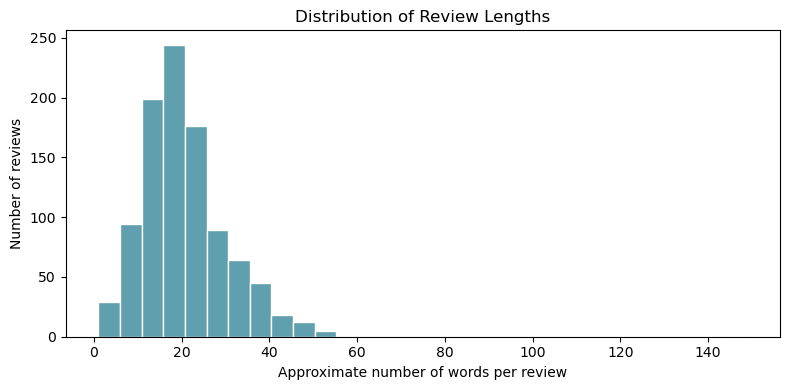


Three shortest reviews:
       Feedback  Word_Count
           Good           1
    Always good           2
Amazing service           2


In [34]:
import matplotlib.pyplot as plt

# Calculate the approximate number of words in each review
df_clean["Word_Count"] = (
    df_clean["Feedback"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

# Display review length statistics
print("Review length summary:")
print(df_clean["Word_Count"].describe().round(1))

print(
    "\nReviews with no words:",
    (df_clean["Word_Count"] == 0).sum()
)

# Plot review lengths
fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(
    df_clean["Word_Count"],
    bins=30,
    color="#609FAD",
    edgecolor="white"
)

ax.set_title("Distribution of Review Lengths")
ax.set_xlabel("Approximate number of words per review")
ax.set_ylabel("Number of reviews")

plt.tight_layout()
plt.show()

# Display the three shortest reviews
print("\nThree shortest reviews:")
print(
    df_clean.nsmallest(3, "Word_Count")[
        ["Feedback", "Word_Count"]
    ].to_string(index=False)
)

### Figure 2: Distribution of Review Lengths

The 977 reviews have an average length of 20.4 words and a median
of 19 words. The middle 50% of reviews contain between 14 and
25 words. Review lengths range from 1 to 149 words, and none
contain zero words.

The distribution has a right-hand tail, indicating that a few
reviews are considerably longer than most. Short reviews such as
“Good” and “Amazing service” still communicate an opinion, although
they provide little detail about particular service issues.

No reviews will be removed solely because of their length.

In [35]:
import re

# Clean the text and keep the original reviews
def clean_text(review):
    review = review.lower()
    review = re.sub(r"https?://\S+|www\.\S+", "", review)
    review = re.sub(r"\s+", " ", review).strip()
    return review

df_clean["Cleaned_Text"] = df_clean["Feedback"].apply(clean_text)

# Check for empty text after cleaning
print("Empty reviews:", (df_clean["Cleaned_Text"] == "").sum())

# Compare the original and cleaned text
df_clean[["Feedback", "Cleaned_Text"]].head()

Empty reviews: 0


,Feedback,Cleaned_Text
0,Good and clean hospital. There is great team of doctors and good OT facility. The medical facilities are all great with good in-patient post opera...,good and clean hospital. there is great team of doctors and good ot facility. the medical facilities are all great with good in-patient post opera...
1,Had a really bad experience during discharge. They need to be sensitive and more transparent towards the patient and his/her family.,had a really bad experience during discharge. they need to be sensitive and more transparent towards the patient and his/her family.
2,I have visited to take my second dose and Process was really smooth. Hospitality from all staffs are really appreciable. Shanti tooks good care an...,i have visited to take my second dose and process was really smooth. hospitality from all staffs are really appreciable. shanti tooks good care an...
3,"That person was slightly clueless and offered only one package. But once i got to the hospital, I found a better and more economical one and deci...","that person was slightly clueless and offered only one package. but once i got to the hospital, i found a better and more economical one and decid..."
4,There is great team of doctors and good OT facility.,there is great team of doctors and good ot facility.


## 5. Preparing the Training and Test Sets

The cleaned review text will be used as the input, and the supplied
Sentiment Label will be the target.

The data will be divided into 80% training data and 20% test data.
The split will preserve approximately the same label proportions
in both sets.

Ratings will not be used as an input because they directly correspond
to the supplied labels. The model should learn from review text instead.

In [36]:
from sklearn.model_selection import train_test_split

# Use the review text to predict the supplied label
X = df_clean["Cleaned_Text"]
y = df_clean["Sentiment Label"]

# Keep some reviews aside for testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training reviews:", len(X_train))
print("Test reviews:", len(X_test))

print("\nTraining labels:")
print(y_train.value_counts().sort_index())

print("\nTest labels:")
print(y_test.value_counts().sort_index())

Training reviews: 781
Test reviews: 196

Training labels:
Sentiment Label
0    212
1    569
Name: count, dtype: int64

Test labels:
Sentiment Label
0     53
1    143
Name: count, dtype: int64


## 6. Feature Extraction and Model Training

I will use TF-IDF to convert the review text into numerical features.
The features will include individual words and pairs of consecutive
words, with a maximum of 3,000 features.

Logistic Regression will be used as a straightforward baseline
clasifier. Balanced class weights will be used because the dataset
contains more examples of label 1 than label 0.

TF-IDF and Logistic Regression will be joined in a pipeline.
The pipeline will be fited using the training data only, keeping
the test data separate for evaluation.

The model will predict the supplied rating aligned labels, which
are not independently verified text sentiments.

In [37]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Convert the text into features, then train the classifier
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=3000,
        ngram_range=(1, 2),
        min_df=2
    )),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Learn from the training reviews only
model.fit(X_train, y_train)

print("Model training is complete.")
print(
    "Number of text features:",
    len(model.named_steps["tfidf"].get_feature_names_out())
)

Model training is complete.
Number of text features: 3000


## 7. Model Evaluation

I will evaluate the model using accuracy, precision, recall, F1-score
and a confusion matrix.

Accuracy shows the overall proportion of correct predictions.
Precision and recall help explain performance for each label.
Macro F1 gives both labels equal weight, which is useful because
the label counts are uneven.

The results measure agreement with the supplied labels, not
independently verified text sentiment.

Accuracy: 0.842

Classification report:
              precision    recall  f1-score   support

     Label 0      0.683     0.774     0.726        53
     Label 1      0.912     0.867     0.889       143

    accuracy                          0.842       196
   macro avg      0.798     0.820     0.807       196
weighted avg      0.850     0.842     0.845       196

Majority-label baseline accuracy: 0.73


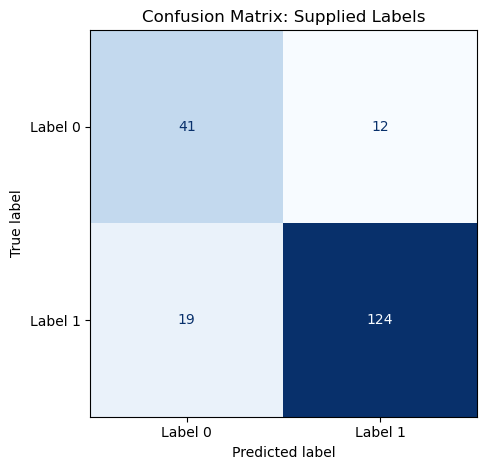

In [38]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict labels for the test reviews
y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Label 0", "Label 1"],
    digits=3,
    zero_division=0
))

# Compare against always predicting the majority training label
majority_label = y_train.mode()[0]
baseline_pred = [majority_label] * len(y_test)

print(
    "Majority-label baseline accuracy:",
    round(accuracy_score(y_test, baseline_pred), 3)
)

# Show correct predictions and errors
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Label 0", "Label 1"],
    cmap="Blues",
    colorbar=False
)

plt.title("Confusion Matrix: Supplied Labels")
plt.tight_layout()
plt.show()

### Evaluation Results

The Logistic Regression pipeline achieved an accuracy of 84.2%
on 196 test reviews. This was esimated at 11.2 percentage point
higher than the majority label baselin accuracy of 73.0%.

The macro F1-score was 0.807. Label 0 had a precision of 0.683,
recall of 0.774 and F1-score of 0.726. Label 1 had a precision
of 0.912, recall of 0.867 and F1-score of 0.889. The model
therefore performed better for label 1 than for label 0.

### Figure 3: Confusion Matrix

The model correctly predicted 41 of the 53 label 0 reviews and
124 of the 143 label 1 reviews. It predicted 12 label 0 reviews
as label 1, and 19 label 1 reviews as label 0.

Overall, 165 predictions matched the supplied labels and 31 did not.
These results measure agreement with the dataset's rating-aligned
labels, not independently verified text sentiment. Earlier checks
showed that some labels disagreed with the review wording, which
limits the interprtation of these scores.

In [39]:
# Keep the test reviews and their results together
results = pd.DataFrame({
    "Review": df_clean.loc[X_test.index, "Feedback"],
    "Rating": df_clean.loc[X_test.index, "Ratings"],
    "Supplied_Label": y_test,
    "Predicted_Label": y_pred
})

# Find predictions that disagree with the supplied labels
errors = results[
    results["Supplied_Label"] != results["Predicted_Label"]
]

print("Number of disagreements:", len(errors))

# Read five examples in full
for _, row in errors.head(5).iterrows():
    print("\nReview:", row["Review"])
    print("Rating:", row["Rating"])
    print("Supplied label:", row["Supplied_Label"])
    print("Predicted label:", row["Predicted_Label"])

Number of disagreements: 31

Review: Other wise no complaints, fully satisfied.
Rating: 4
Supplied label: 1
Predicted label: 0

Review: I came in with bad kidney pain and got help immediately Had a brief stay in the ER that was quite good.
Rating: 2
Supplied label: 0
Predicted label: 1

Review: if we continue our visit next time Do I get assurances from hospital the patient will be treated properly.
Rating: 3
Supplied label: 1
Predicted label: 0

Review: A lot can improve in this place to make the experience great.
Rating: 3
Supplied label: 1
Predicted label: 0

Review: The parking is very limited with space for 10 15 cars with lot of bird droppings falling on the car.
Rating: 3
Supplied label: 1
Predicted label: 0


## 8. Identifying Common Review Topics

NMF topic modelling will be used to explore recurring themes in
the reviews. The model will start with four topics.

The most important words and example reviews will be inspected
before giving each topic a meaningful name. Four topics is an
initial modelling choice, not a confirmed number of service issues.

Topics may include praise as well as complaints. A topic will
only be described as an area of concern after checking the
associated review text.

This is a separate exploratory analysis and will not change
the sentiment classifier or its test results.

In [40]:
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer

# Create separate text features for topic modelling
topic_vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=2000,
    min_df=2,
    max_df=0.95
)

topic_features = topic_vectorizer.fit_transform(
    df_clean["Cleaned_Text"]
)

topic_model = NMF(
    n_components=4,
    init="random",
    solver="mu",
    random_state=42,
    max_iter=500
)
)

topic_scores = topic_model.fit_transform(topic_features)

# Show the main words and two example reviews for each topic
words = topic_vectorizer.get_feature_names_out()

for number, topic in enumerate(topic_model.components_):
    top_words = topic.argsort()[-8:][::-1]

    print(f"\nTopic {number + 1}")
    print("Main words:", ", ".join(words[top_words]))

    examples = topic_scores[:, number].argsort()[-2:][::-1]

    for position in examples:
        print("Example:", df_clean.iloc[position]["Feedback"])

<class 'SyntaxError'>: unmatched ')' (<ipython-input-40-63f415a9e550>, line 23)

In [ ]:
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer

# Prepare the text for topic modelling
topic_vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=2000,
    min_df=2,
    max_df=0.95
)

topic_features = topic_vectorizer.fit_transform(
    df_clean["Cleaned_Text"]
)

# Create four starting topics
topic_model = NMF(
    n_components=4,
    init="random",
    solver="mu",
    random_state=42,
    max_iter=500
)

topic_scores = topic_model.fit_transform(topic_features)

# Show the main words and example reviews
words = topic_vectorizer.get_feature_names_out()

for number, topic in enumerate(topic_model.components_):
    top_words = topic.argsort()[-8:][::-1]

    print(f"\nTopic {number + 1}")
    print("Main words:", ", ".join(words[top_words]))

    examples = topic_scores[:, number].argsort()[-2:][::-1]

    for position in examples:
        print("Example:", df_clean.iloc[position]["Feedback"])

### Initial Topic Interpretation

The four-topic model produced the following provisional themes:

| Topic | Provisional name | Interpretation |
|---|---|---|
| 1 | Staff helpfulness and hospital environment | The example reviews praise friendly staff, competent doctors and the hospital environment. |
| 2 | Treatment and nursing care | The examples describe appreciation for treatment, nursing care and support. |
| 3 | General service satisfaction | The examples contain brief positive comments such as “Good” and “Always good”, with little detail. |
| 4 | Negative hospital experiences | The main terms and examples indicate dissatisfaction, but the examples do not explain its specific causes. |

These names are interpretations of the model output, not verified
service categories. The model appears to separate positive and
negative language as well as service-related themes. Topics 1–3
also overlap, so the four-topic solution is only a starting point.

More detailed reviews associated with Topic 4 will be inspected
to identify specific areas of concern.

In [ ]:
# Keep a separate table for inspecting the negative-experience topic
concern_reviews = df_clean[
    ["Feedback", "Ratings", "Sentiment Label", "Word_Count"]
].copy()

# Topic 4 is column 3 because Python counts from zero
concern_reviews["Topic_4_Score"] = topic_scores[:, 3]

# Read longer examples to understand the actual issues
detailed_reviews = concern_reviews[
    concern_reviews["Word_Count"] >= 15
].sort_values("Topic_4_Score", ascending=False)

for _, row in detailed_reviews.head(8).iterrows():
    print("\nReview:", row["Feedback"])
    print("Rating:", row["Ratings"])
    print("Supplied label:", row["Sentiment Label"])

### Detailed Review of the Negative-Experience Topic

The selected reviews mention staff-related dissatisfaction, time
wasted, high charges and uncertainty about when a doctor would
see the patient. One review describes a negative emergency-ward
experience without explaining the specific problem.

Some reviews contain mixed opinions, such as praise for doctors
alongside criticism of other services. These examples suggest
possible areas for further investigation, but do not establish
how common each concern is across the full dataset.

Two examples contain identical review text but different ratings
and sentiment labels. This reveals an additional data-quality
issue that was not detected by removing exact duplicate rows.

In [ ]:
# Check repeated text, even when ratings or labels differ
text_groups = df_clean.groupby("Cleaned_Text").agg(
    Review_Count=("Feedback", "size"),
    Different_Labels=("Sentiment Label", "nunique")
)

repeated_text = text_groups[text_groups["Review_Count"] > 1]
conflicting_text = text_groups[text_groups["Different_Labels"] > 1]

print("Repeated text groups:", len(repeated_text))
print("Text groups with conflicting labels:", len(conflicting_text))

# Check whether the same text appears in both data splits
shared_text = set(X_train) & set(X_test)

print("Text shared by training and test sets:", len(shared_text))
print(
    "Test reviews with text also in training:",
    X_test.isin(shared_text).sum()
)

# Display a few conflicting examples
conflict_examples = df_clean[
    df_clean["Cleaned_Text"].isin(conflicting_text.index)
].sort_values("Cleaned_Text")

conflict_examples[
    ["Feedback", "Ratings", "Sentiment Label"]
].head(10)

## 9. Additional Cleaning and Revised Evaluation

Further checks identified 27 groups of repeated review text.
Five groups contained conflicting sentiment labels. Five test
reviews also had identical cleaned text in the training set.

For the revised clasification analysis, all reviews in the
conflicting-label groups will be excluded because their correct
labels cannot be established from the available data. Remaining
repeated text will be reduced to one record per cleaned review.

The classifier will then be retrained using a new split with the
same settings. This revisin addreses data quality rather than
tuning the model to improve its score.

The revised evaluation is stil exploratory because the earlier
test results have already been inspected. Removing conflicting
labels also does not resolve every possible labeling error.

In [ ]:
# Find text with more than one supplied label
label_counts = df_clean.groupby(
    "Cleaned_Text"
)["Sentiment Label"].nunique()

conflict_text = label_counts[label_counts > 1].index

# Keep the earlier dataset unchanged
df_model = df_clean[
    ~df_clean["Cleaned_Text"].isin(conflict_text)
].copy()

print("Rows excluded for conflicting labels:",
      len(df_clean) - len(df_model))

# Keep one copy of each remaining cleaned review
before = len(df_model)
df_model = df_model.drop_duplicates(
    subset="Cleaned_Text"
).reset_index(drop=True)

print("Additional repeated rows removed:", before - len(df_model))
print("Final modelling rows:", len(df_model))

print("\nRemaining label counts:")
print(df_model["Sentiment Label"].value_counts().sort_index())

In [ ]:
from sklearn.base import clone

X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    df_model["Cleaned_Text"],
    df_model["Sentiment Label"],
    test_size=0.2,
    random_state=42,
    stratify=df_model["Sentiment Label"]
)

# Check that identical cleaned text is no longer shared
overlap = set(X_train_new) & set(X_test_new)
print("Text shared between sets:", len(overlap))

# Use the same pipeline settings as before
revised_model = clone(model)
revised_model.fit(X_train_new, y_train_new)

print("Revised model training complete.")
print("Training reviews:", len(X_train_new))
print("Test reviews:", len(X_test_new))

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict using the revised model
y_pred_new = revised_model.predict(X_test_new)

print(
    "Revised accuracy:",
    round(accuracy_score(y_test_new, y_pred_new), 3)
)

print("\nRevised classification report:")
print(classification_report(
    y_test_new,
    y_pred_new,
    labels=[0, 1],
    target_names=["Label 0", "Label 1"],
    digits=3,
    zero_division=0
))

# Check the majority-label baseline for this new test set
majority_label_new = y_train_new.mode()[0]
baseline_new = [majority_label_new] * len(y_test_new)

print(
    "Revised baseline accuracy:",
    round(accuracy_score(y_test_new, baseline_new), 3)
)

# Display the revised confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test_new,
    y_pred_new,
    labels=[0, 1],
    display_labels=["Label 0", "Label 1"],
    cmap="Blues",
    colorbar=False
)

plt.title("Revised Model: Confusion Matrix")
plt.tight_layout()
plt.show()

### Revised Model Evaluation

After additional cleaning, the classifier achieved 87.3% accuracy
on 189 test reviews. This was approximately 14.3 percentage points
above the majority-label baseline accuracy of 73.0%.

The macro F1-score was 0.848. Label 0 had a precision of 0.721,
recall of 0.863 and F1-score of 0.786. Label 1 had a precision
of 0.945, recall of 0.877 and F1-score of 0.910.

The model performed better for label 1 overall. Its lower precision
for label 0 indicates that some reviews predicted as label 0 had
a supplied label of 1.

### Figure 4: Revised Confusion Matrix

The model correctly predicted 44 of the 51 label 0 reviews and
121 of the 138 label 1 reviews. Seven label 0 reviews were
predicted as label 1, while 17 label 1 reviews were predicted
as label 0.

### Interpretation and Limitations

The revised evaluation used a dataset with conflicting-label
groups excluded and remaining repeated text reduced to one record
per cleaned review. No identical cleaned text was shared between
the revised training and test sets.

The revised accuracy was higher than the preliminary accuracy,
but the dataset and test split changed. The difference therefore
cannot be attributed solely to better model performance.

The model settings were unchanged; the revision addressed data
quality rather than hyperparameter tuning. The evaluation remains
exploratory because earlier test results were already inspected.

The supplied labels are rating-aligned and are not independently
verified text sentiments. Remaining label errors may still affect
the results.

In [ ]:
# Save the revised modelling dataset
df_model.to_csv("hospital_model_data.csv", index=False)

# Save the revised test predictions
final_results = pd.DataFrame({
    "Review": df_model.loc[X_test_new.index, "Feedback"],
    "Supplied_Label": y_test_new,
    "Predicted_Label": y_pred_new
})

final_results.to_csv("revised_test_predictions.csv", index=False)

print("The modelling data and test predictions have been saved.")

## 10. Topic Summary

Each review will be assigned to the topic with its highest NMF
weight for a simple descriptive summary. Reviews with no topic
weight will be marked as unassigned.

These assignments are approximate. A review can discuss several
issues, and the topic counts do not represent verified complaint
counts or sentiment percentages.

This topic summary uses the 977-review exploratory dataset.
The revised classifier uses the separate 945-review modelling dataset.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Keep the topic results separate from the modelling data
topic_results = df_clean.copy()

topic_names = {
    0: "Staff and environment",
    1: "Treatment and nursing care",
    2: "General satisfaction",
    3: "Negative experiences"
}

# Use the strongest topic for each review
topic_results["Main_Topic"] = (
    pd.Series(topic_scores.argmax(axis=1), index=topic_results.index)
    .map(topic_names)
)

# Do not assign reviews with no topic weight
no_topic = topic_scores.sum(axis=1) == 0
topic_results.loc[no_topic, "Main_Topic"] = "Unassigned"

topic_counts = topic_results["Main_Topic"].value_counts()

print("Reviews assigned to each main topic:")
print(topic_counts)

fig, ax = plt.subplots(figsize=(9, 5))
topic_counts.sort_values().plot.barh(ax=ax, color="#609FAD")

ax.set_title("Main Topic Assigned to Each Review")
ax.set_xlabel("Number of reviews")
ax.set_ylabel("")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, f1_score

# Save the revised classifier's test predictions
final_results = pd.DataFrame({
    "Review": df_model.loc[X_test_new.index, "Feedback"],
    "Supplied_Label": y_test_new,
    "Predicted_Label": y_pred_new
})

# Save a short summary of the revised evaluation
score_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Macro F1", "Majority baseline accuracy"],
    "Score": [
        accuracy_score(y_test_new, y_pred_new),
        f1_score(y_test_new, y_pred_new, average="macro"),
        accuracy_score(y_test_new, baseline_new)
    ]
})

df_model.to_csv("hospital_model_data.csv", index=False)
final_results.to_csv("revised_test_predictions.csv", index=False)
topic_results.to_csv("hospital_topic_results.csv", index=False)
topic_counts.rename_axis("Topic").to_csv("topic_counts.csv")
score_summary.to_csv("revised_model_scores.csv", index=False)

print("All five CSV files have been saved.")
print(score_summary.round(3))

### Topic Model Evaluation

The topic model was assessed qualitatively by inspecting its main
words and associated reviews. It produced interpretable themes
relating to staff, treatment, general satisfaction and negative
experiences.

However, the positive themes overlap, and the negative-experience
topic does not consistently separate specific service problems.
The model is therefore useful for initial exploration rather than
a reliable ranking of complaint categories.

Four topics were used as a starting point. This analysis does not
establish that four is the optimal number of topics. A fuller
evaluation would compare different topic counts and use a broader
manual review of the assignments.

## 11. Conclusion and Recommendations

This project used text analysis to explore hospital reviews and
predict the dataset's supplied sentiment labels.

Data-quality checks identified an empty column, duplicate rows,
repeated review text and conflicting labels. After additional
cleaning, the classification dataset contained 945 reviews.

The revised TF-IDF and Logistic Regression pipeline achieved
87.3% accuracy and a macro F1-score of 0.848 on 189 test reviews.
Its accuracy exceeded the majority-label baseline of 73.0%.
However, these results measure agreement with rating-aligned
labels rather than independently verified text sentiment.

Topic modelling identified provisional themes relating to staff
and the hospital environment, treatment and nursing care, general
satisfaction and negative experiences. Inspection of selected
reviews suggested concerns about staff interactions, time wasted,
charges and communication about doctor availability. These
examples do not establish the frequency or ranking of complaints.

### Recommendations

The reviewed concerns suggest investigating communication about
doctor availability, staff responsiveness and explanations of
charges. These are areas for further investigation, not confirmed
causes of poor service across all hospitals.

Before practical use, the review labels should be manually
validated. Topic categories should also be checked against a
broader sample of reviews.

### Limitations

The dataset concerns hospitals in Bengaluru, India, rather than
South African medical-aid providers. Its findings cannot be
generalised to medical-aid members.

Other limitations include uneven label counts, possible remaining
label errors, overlapping topics and the use of one revised
train-test split. The revised evaluation remains exploratory
because earlier test results were inspected.

Future work should use relevant medical-aid reviews, independently
checked sentiment labels and a new evaluation dataset.

In [41]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
import numpy as np
import pandas as pd

count_vec = CountVectorizer(stop_words="english", min_df=2, max_df=0.95)
X_counts = count_vec.fit_transform(df_clean["Cleaned_Text"])

lda = LatentDirichletAllocation(
    n_components=4,
    learning_method="batch",
    max_iter=20,
    random_state=42
)
lda_scores = lda.fit_transform(X_counts)

terms = count_vec.get_feature_names_out()
for i, comp in enumerate(lda.components_):
    top = [terms[j] for j in comp.argsort()[-10:][::-1]]
    print(f"Topic {i + 1}:", ", ".join(top))

print("Vocabulary size:", len(terms))
print("Perplexity:", round(lda.perplexity(X_counts), 1))

Topic 1: staff, doctor, patients, care, appointment, time, good, doctors, treatment, dr
Topic 2: hospital, patient, care, service, excellent, experience, doctor, treatment, health, doctors
Topic 3: dr, good, hospital, treatment, team, experience, really, happy, services, thanks
Topic 4: hospital, good, staff, doctors, service, worst, experience, emergency, helpful, clean
Vocabulary size: 1083
Perplexity: 617.4


In [42]:
df_lda = df_clean.copy()
df_lda["LDA_Topic"] = lda_scores.argmax(axis=1) + 1
df_lda["Topic_Weight"] = lda_scores.max(axis=1)

for t in range(1, 5):
    print(f"\n--- LDA Topic {t} ---")
    subset = df_lda[df_lda["LDA_Topic"] == t].sort_values("Topic_Weight", ascending=False)
    for review in subset["Feedback"].head(5):
        print("-", review[:200])

print(df_lda["LDA_Topic"].value_counts().sort_index())


--- LDA Topic 1 ---
- Highly Disappointed for Security Service very arrogant speaks for all securities and admission counter Are very waste for Customer support Not given Solutions for ward Booking Billing Manager Ram is v
- Highly Disappointed for Security Service very arrogant speaks for all securities and admission counter Are very waste for Customer support Not given Solutions for ward Booking Billing Manager Ram is v
- I took an appointment for 11 am and its now 12:30 pm but still didn't got to see doctor, the ladies in reception are so rude that they do not care if the patient is suffering due to their delay in bil
- I have consulted Dr Karthik sir I would say one of best doctor near HSR He do systematic examination no hurry explains issue calmy and won't suggest unnecessary test.
- Visited Naraya hrudayalaya for health checkup during the weekend Usually very crowded and took around 5-6 hours for complete routine checkup Staff is supportive and cleanliness is maintained.

--- LD

## LDA Topic Interpretation and Evaluation

The LDA model produced four topics from the 977-review exploratory
dataset. Topic names were assigned after inspecting the top words
and selected example reviews.

| Topic | Provisional interpretation | Assigned reviews |
|---|---|---:|
| 1 | Staff interactions and appointment experiences | 197 |
| 2 | Patient care, facilities and billing experiences | 238 |
| 3 | Doctors, treatment and check-up experiences | 233 |
| 4 | General hospital, inpatient and emergency experiences | 309 |

Selected reviews described concerns about appointment delays,
staff interactions, cleanliness, facilities and billing. Other
reviews praised doctors, treatment and nursing care. These are
examples of experiences discussed, not a ranking of complaints.

The topics were not clearly separated. Similar words appeared
across several topics, and each topic contained different opinions.
Some displayed examples were repeated or closely similar, showing
that repeated text remains a limitation of the exploratory dataset.

Each review was assigned to its highest-probability topic for a
simple summary. The counts do not represent unique customers,
verified complaints or sentiment percentages.

Four topics were used as an initial setting. This analysis did not
establish that four is the best number of topics. Further evaluation
could compare topic counts and inspect a wider range of reviews.

The LDA results support initial exploration of hospital experiences,
but they do not directly describe medical-aid member concerns.

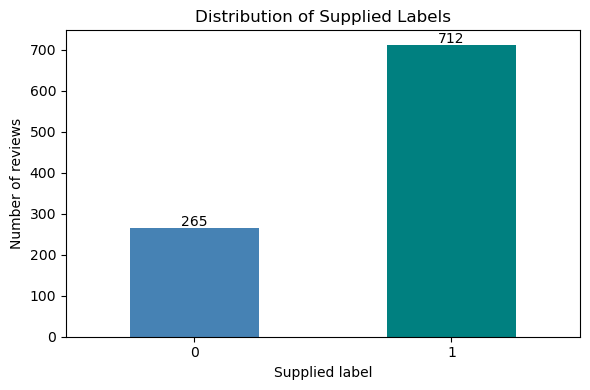

In [43]:
import matplotlib.pyplot as plt

label_counts = (
    df_clean["Sentiment Label"]
    .value_counts()
    .sort_index()
)

ax = label_counts.plot(
    kind="bar",
    color=["steelblue", "teal"],
    rot=0,
    figsize=(6, 4)
)

ax.set_title("Distribution of Supplied Labels")
ax.set_xlabel("Supplied label")
ax.set_ylabel("Number of reviews")

for position, count in enumerate(label_counts):
    ax.text(position, count + 5, str(count), ha="center")

plt.tight_layout()
plt.show()